# Prevendo o peso de pinguins com regressão linear

**Objetivo:** prever o peso (`body_mass_g`) de um pinguim a partir das medidas do bico e da nadadeira, da espécie, da ilha e do sexo.

**Dados:** o dataset *Palmer Penguins*, que vem com a biblioteca seaborn. Cada linha é um pinguim de uma de três espécies (Adelie, Chinstrap e Gentoo), observado em uma de três ilhas da Antártida (Biscoe, Dream e Torgersen).

| Coluna | Significado |
|---|---|
| `bill_length_mm` | comprimento do bico (mm) |
| `bill_depth_mm` | altura do bico (mm) |
| `flipper_length_mm` | comprimento da nadadeira (mm) |
| `body_mass_g` | peso (g), a variável que vamos prever |

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
penguim = sns.load_dataset('penguins')
penguim.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
penguim.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


## 1. Análise exploratória

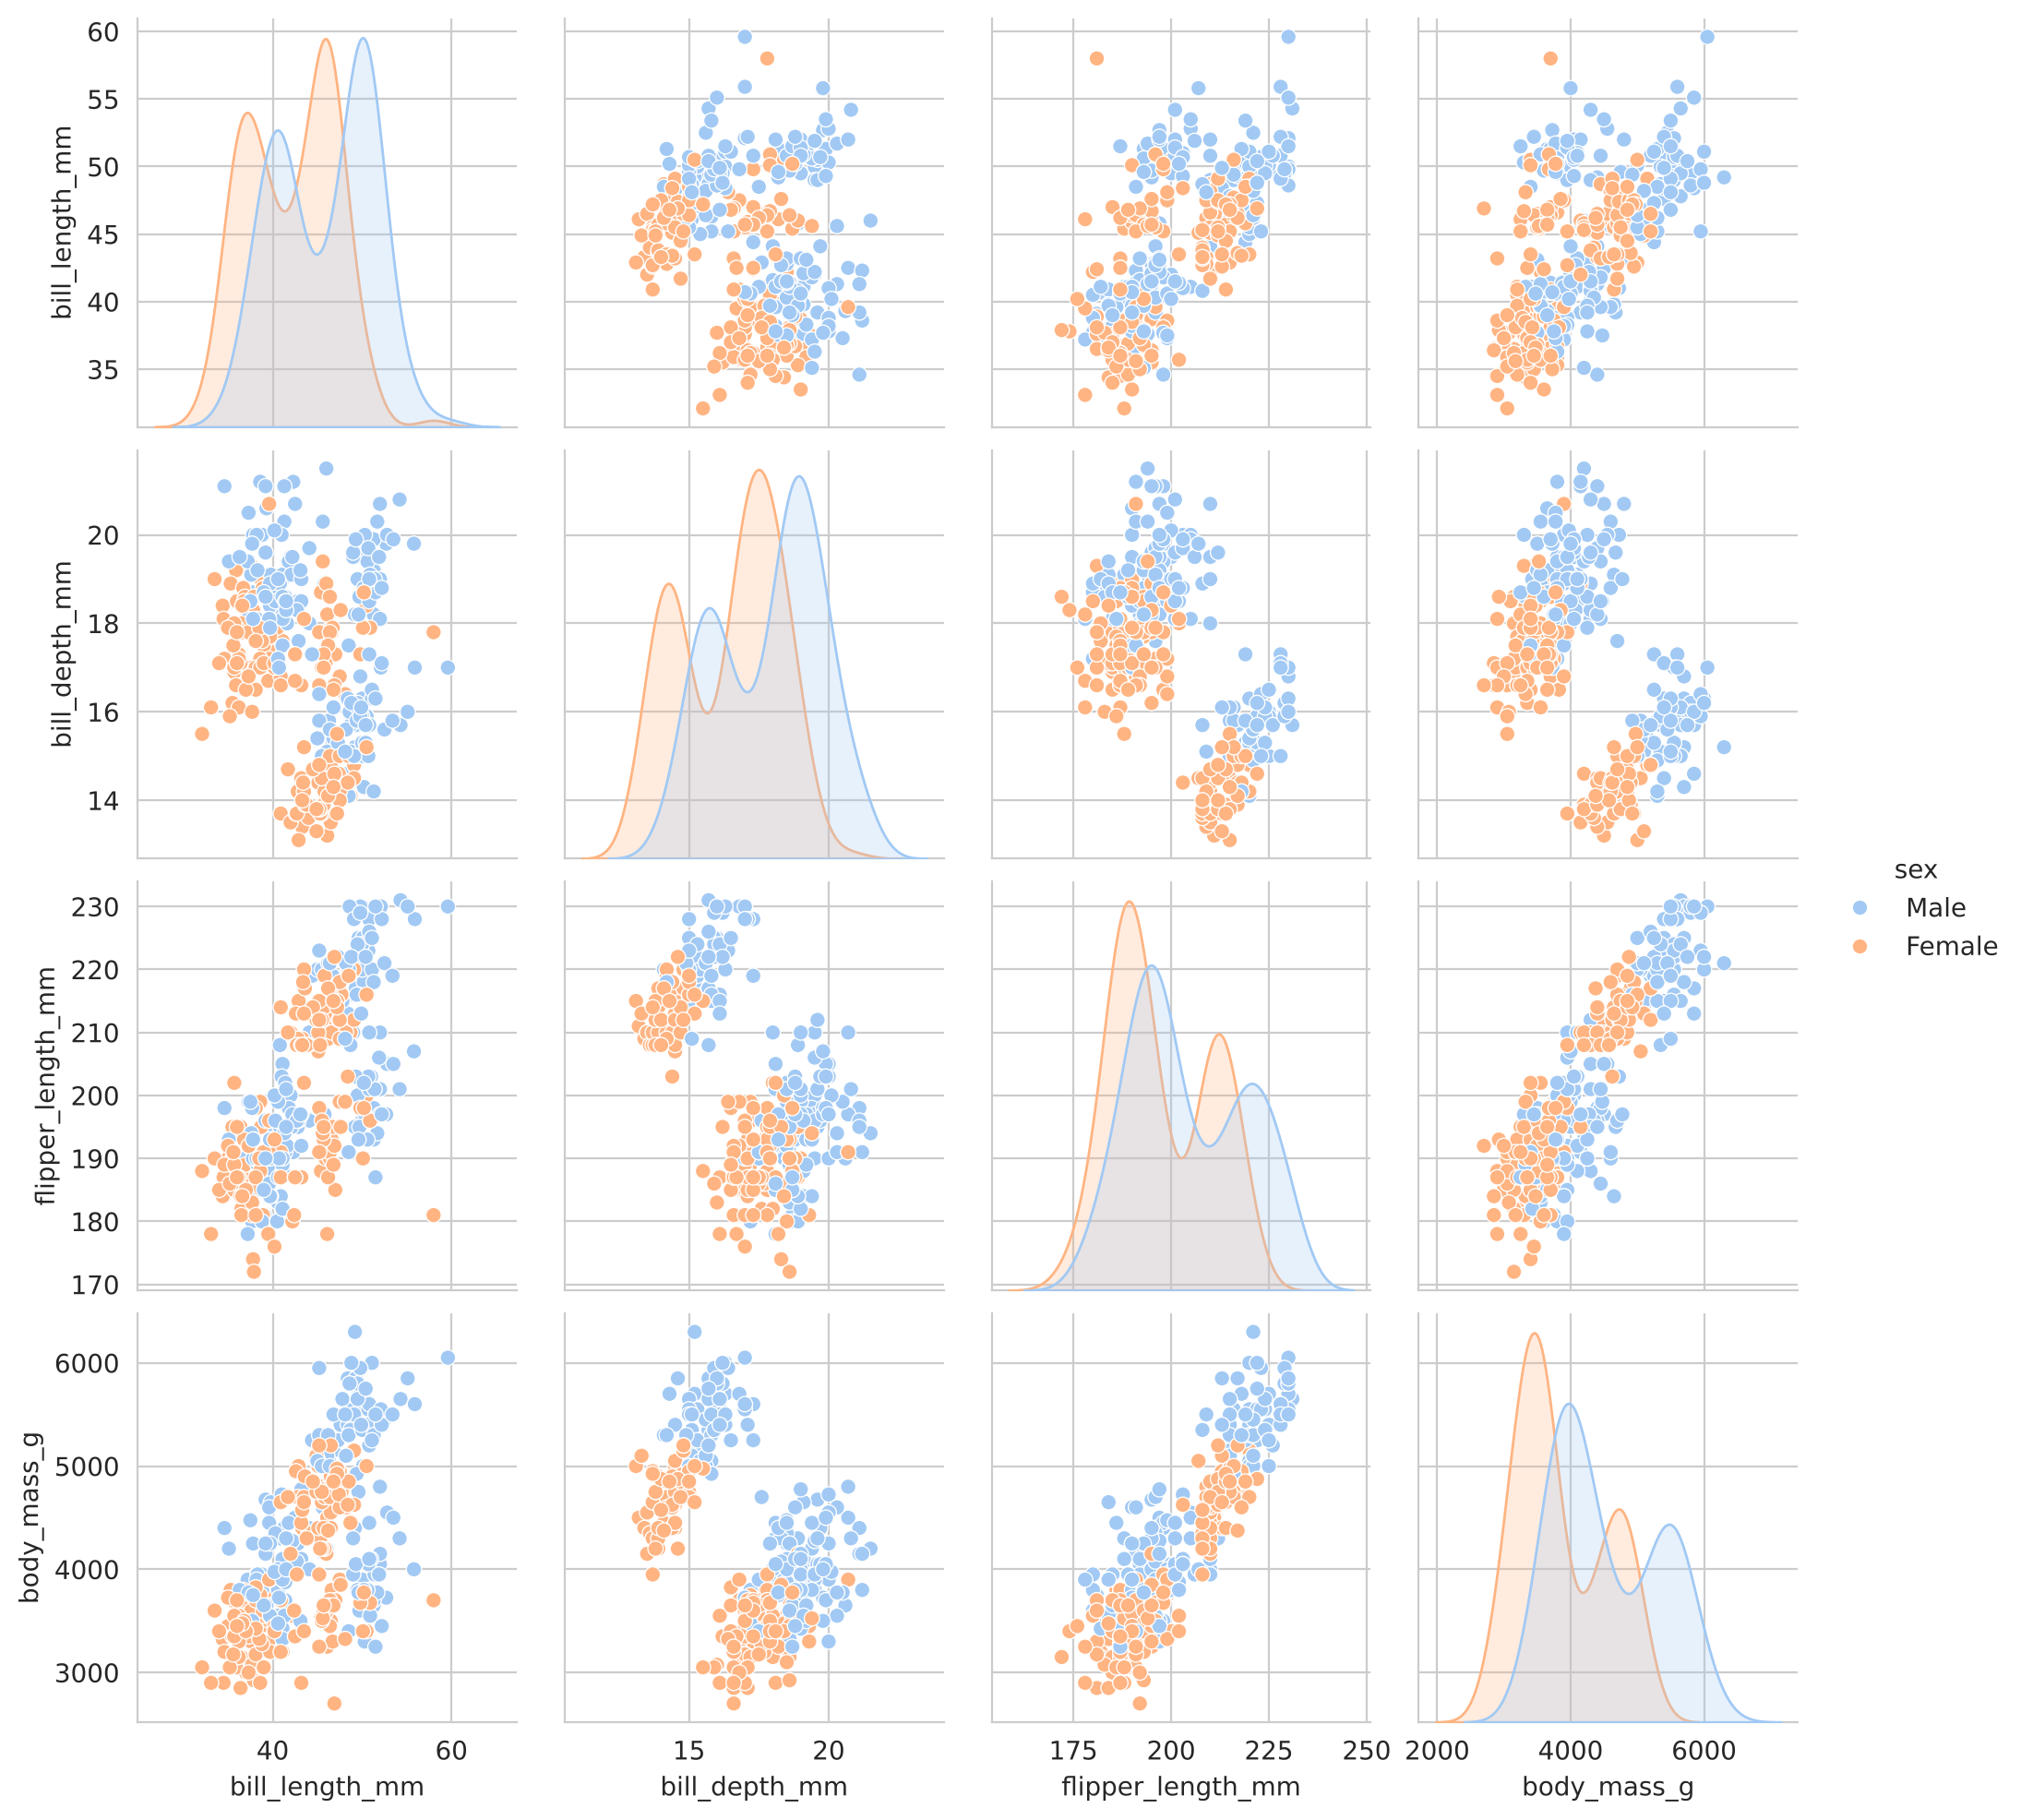

In [4]:
with sns.axes_style('whitegrid'):
    grafico = sns.pairplot(data=penguim, hue='sex', palette='pastel')

Os **machos** tendem a ser mais pesados que as **fêmeas**. Também dá para ver que, quanto maiores o bico (`bill_length_mm`) e a nadadeira (`flipper_length_mm`), mais pesado é o pinguim.

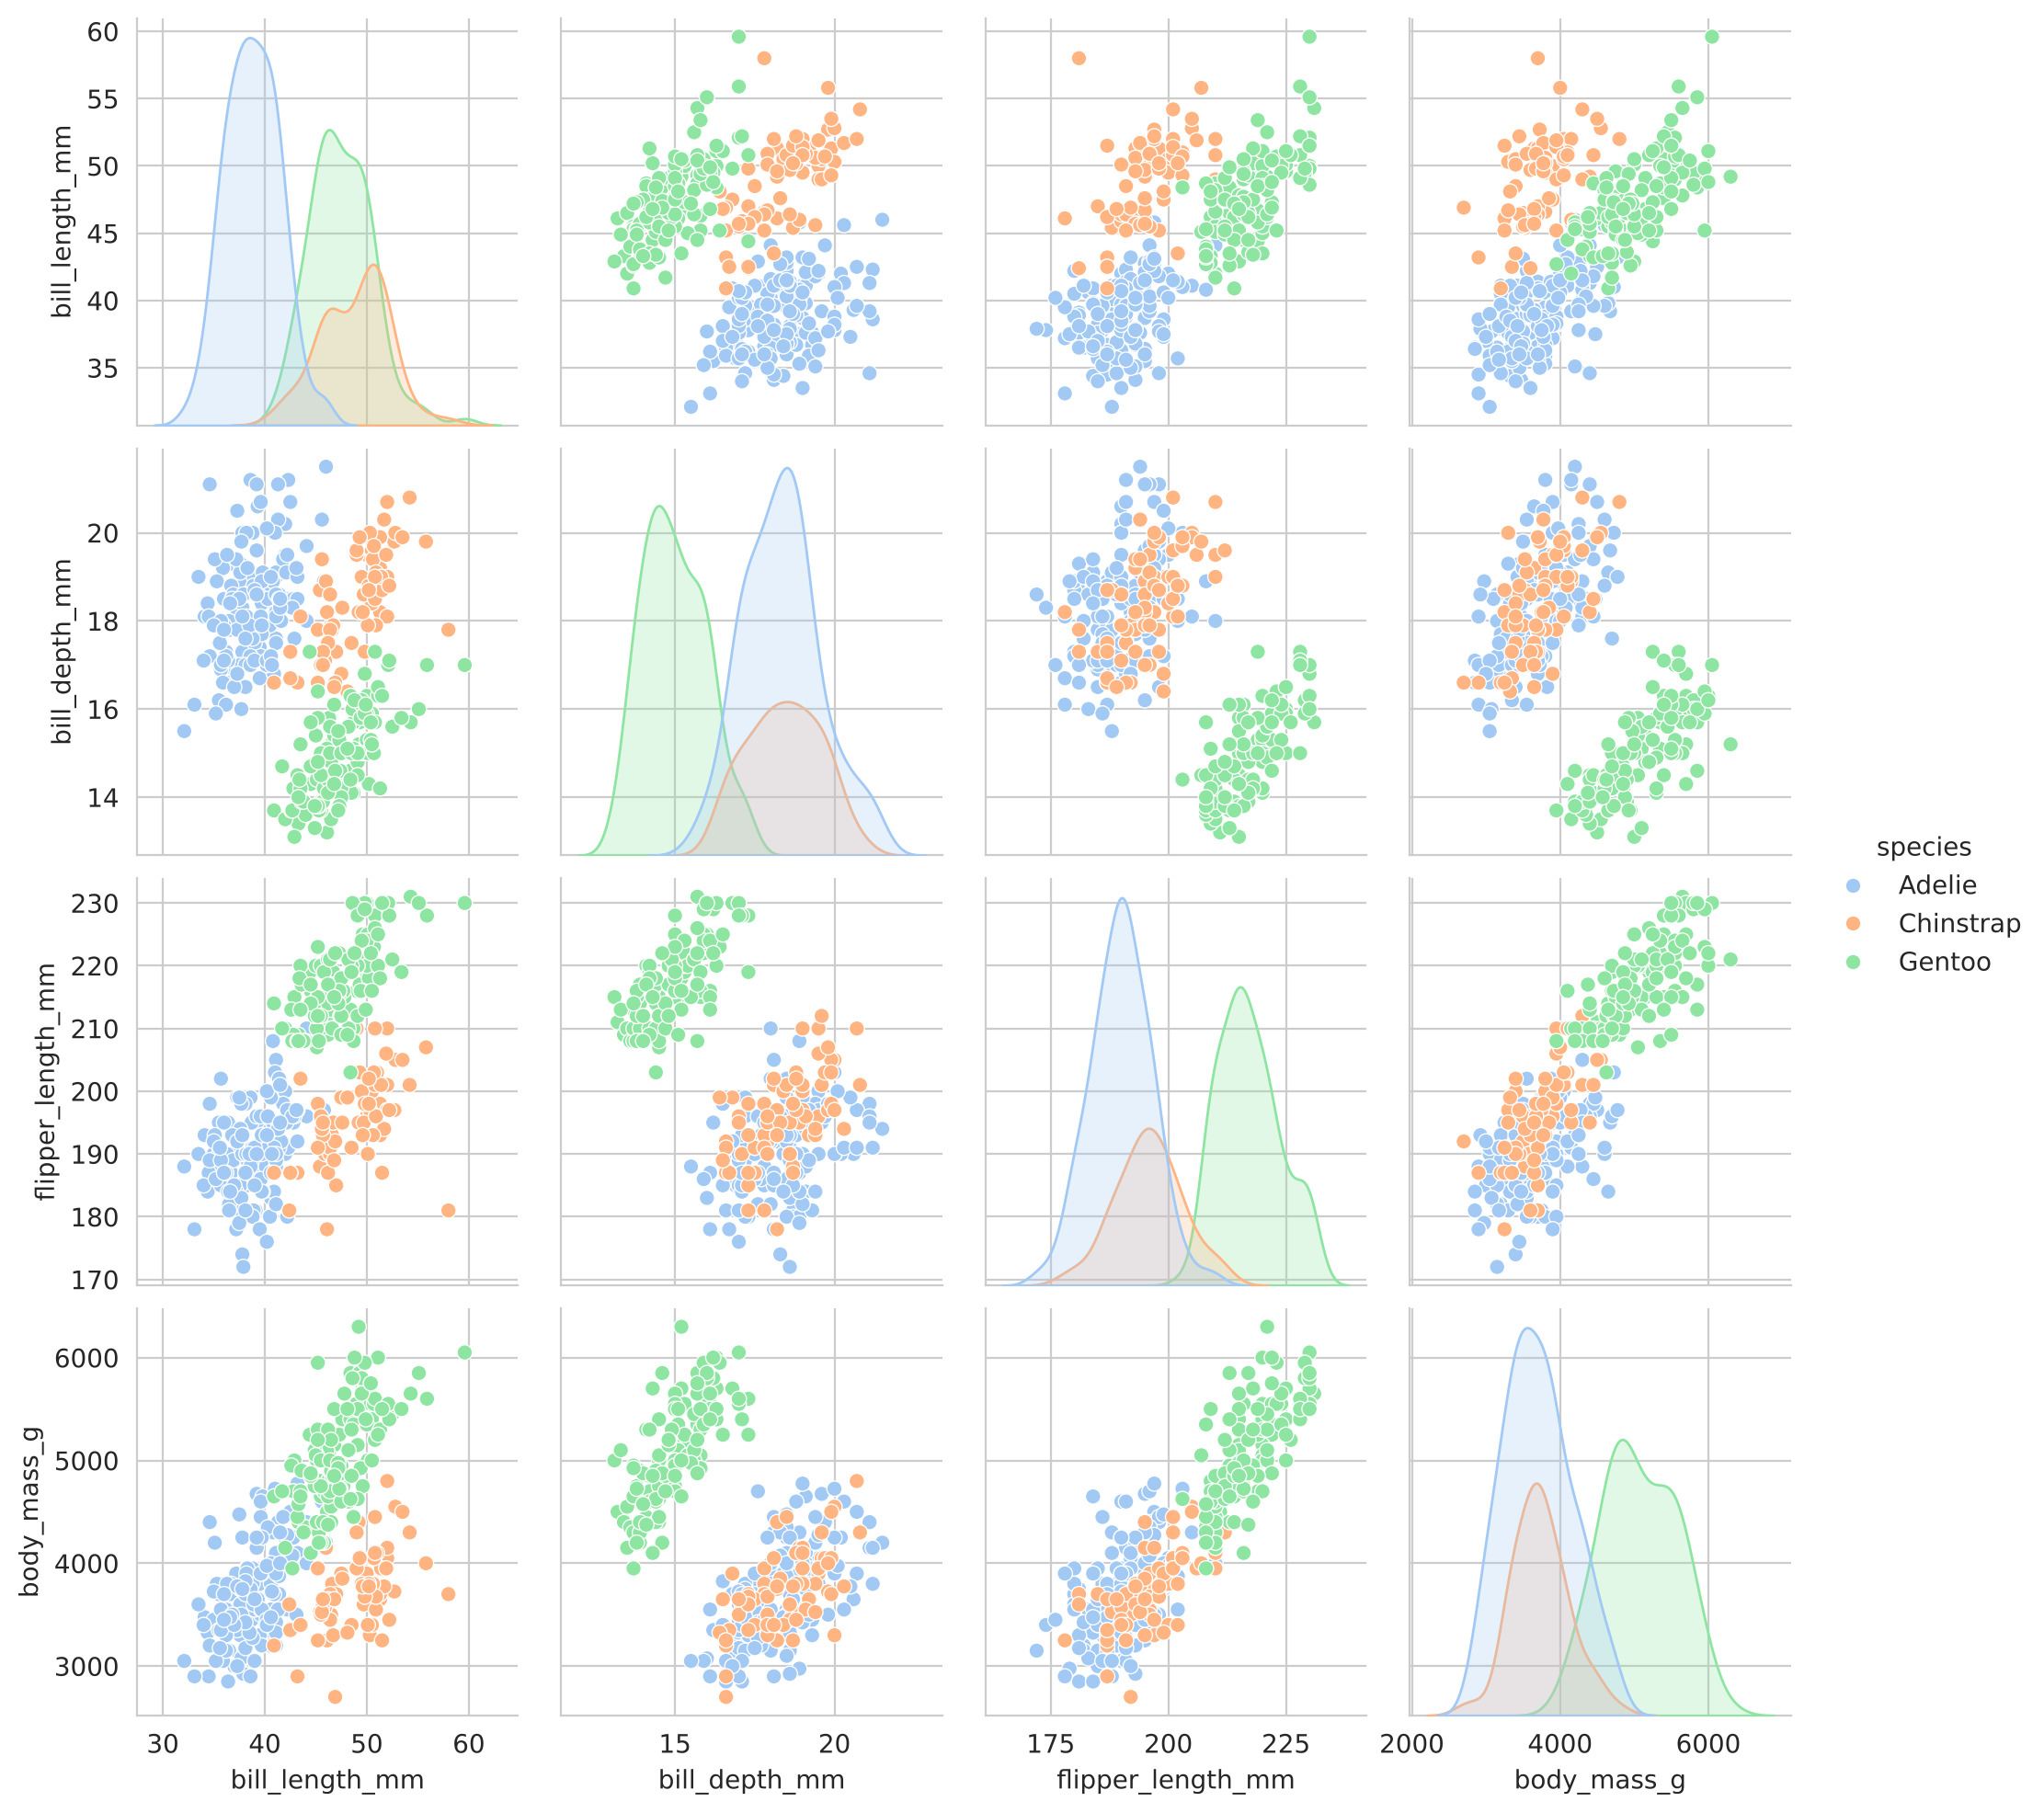

In [5]:
with sns.axes_style('whitegrid'):
    grafico = sns.pairplot(data=penguim, hue='species', palette='pastel')

A **Gentoo** é a espécie mais pesada **entre as três do dataset**, e também tem as nadadeiras mais compridas. Adelie e Chinstrap têm pesos parecidos.

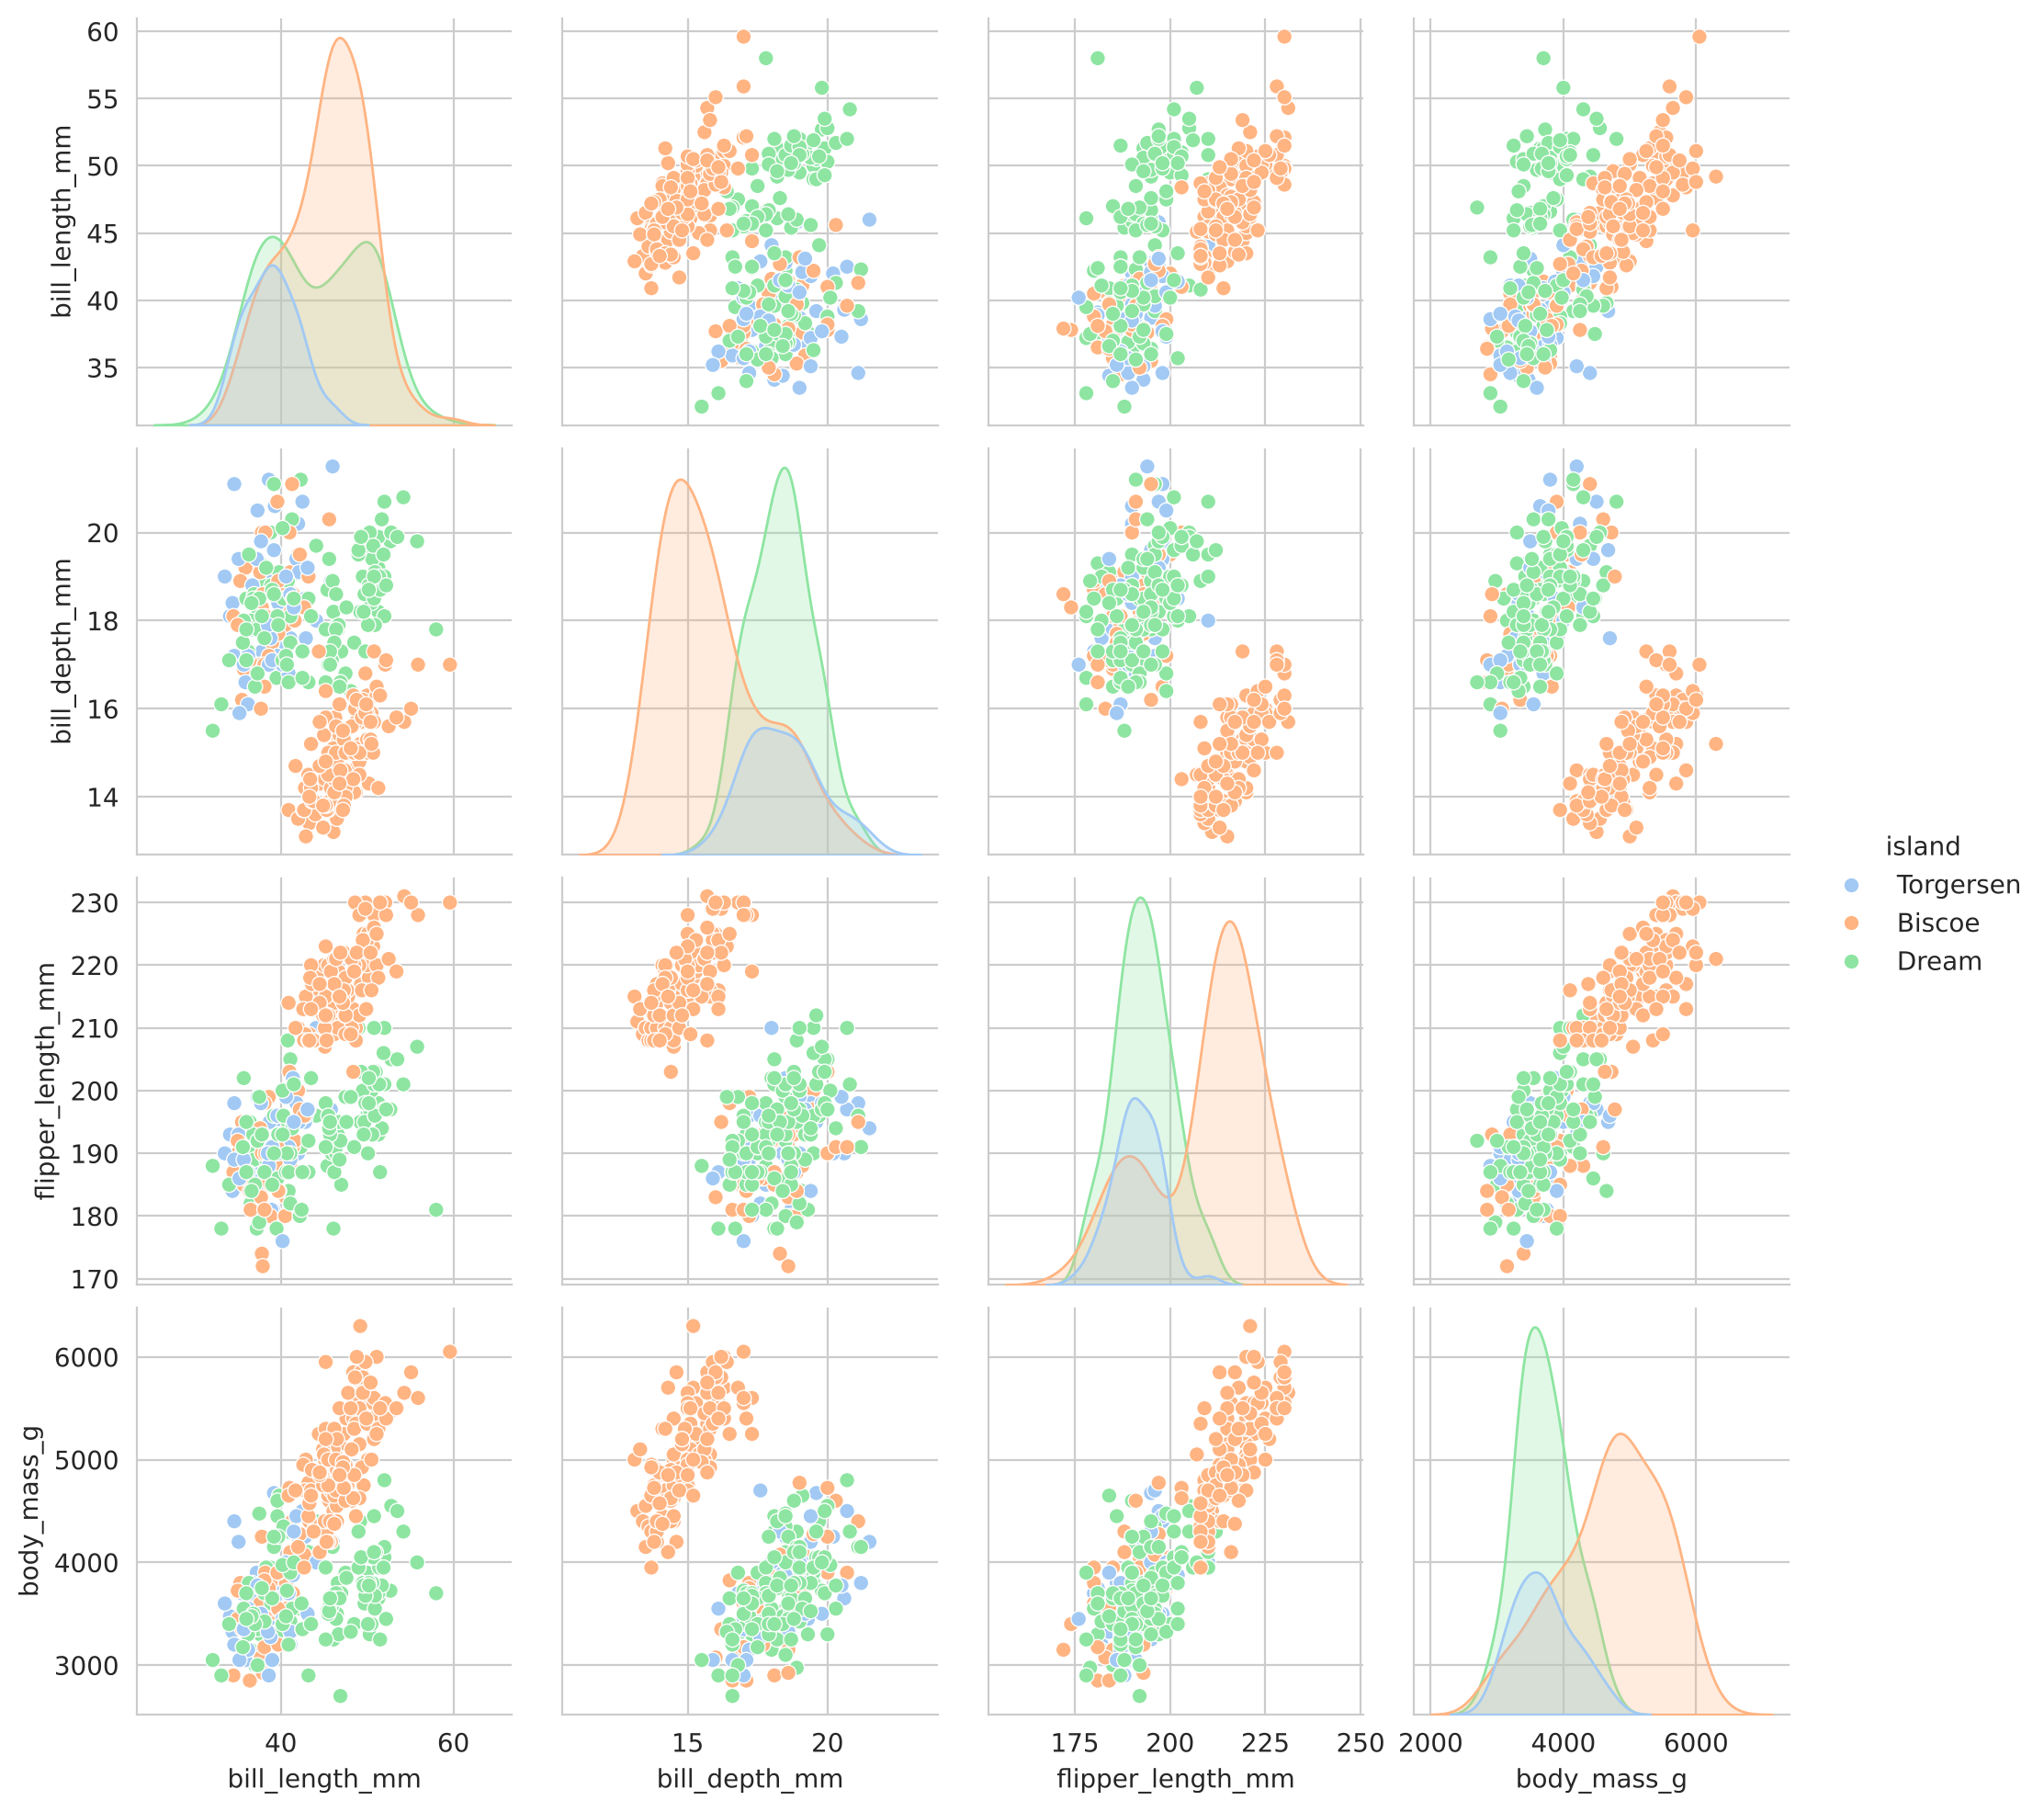

In [6]:
with sns.axes_style('whitegrid'):
    grafico = sns.pairplot(data=penguim, hue='island', palette='pastel')

Pelo gráfico, os pinguins da ilha **Biscoe** parecem os mais pesados. Antes de concluir que a ilha influencia o peso, vale conferir **quais espécies vivem em cada ilha**:

In [7]:
pd.crosstab(penguim['island'], penguim['species'])

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


In [8]:
penguim.groupby('species')['body_mass_g'].mean().round(0)

species
Adelie       3701.0
Chinstrap    3733.0
Gentoo       5076.0
Name: body_mass_g, dtype: float64

Todos os **Gentoo** (a espécie mais pesada, com média de 5.076 g) vivem em **Biscoe**. Ou seja, os pinguins de Biscoe não são mais pesados por causa da ilha, e sim porque é lá que estão os Gentoo.

A espécie é uma **variável de confusão**: ela está ligada, ao mesmo tempo, à ilha e ao peso. Por isso, só pelo gráfico não dá para concluir que a ilha influencia o peso.

## 2. Preparação dos dados

In [9]:
linhas_antes = len(penguim)
penguim = penguim.dropna()
print(f'Linhas removidas por valores faltando: {linhas_antes - len(penguim)}')
print(f'Linhas restantes: {len(penguim)}')

Linhas removidas por valores faltando: 11
Linhas restantes: 333


As colunas de texto (espécie, ilha e sexo) viram colunas de 0 e 1. Com `drop_first=True`, uma categoria de cada grupo fica de fora e vira a **referência**: se um pinguim não é Chinstrap nem Gentoo, ele só pode ser Adelie. Manter todas as colunas criaria informação repetida e deixaria os coeficientes do modelo impossíveis de interpretar.

In [10]:
penguim = pd.get_dummies(penguim, columns=['species', 'island', 'sex'], drop_first=True, dtype=int)
penguim.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,species_Chinstrap,species_Gentoo,island_Dream,island_Torgersen,sex_Male
0,39.1,18.7,181.0,3750.0,0,0,0,1,1
1,39.5,17.4,186.0,3800.0,0,0,0,1,0
2,40.3,18.0,195.0,3250.0,0,0,0,1,0
4,36.7,19.3,193.0,3450.0,0,0,0,1,0
5,39.3,20.6,190.0,3650.0,0,0,0,1,1


In [11]:
x = penguim.drop(columns=['body_mass_g'])
y = penguim['body_mass_g']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.25, random_state=123)
print(f'Treino: {len(x_treino)} pinguins | Teste: {len(x_teste)} pinguins')

Treino: 249 pinguins | Teste: 84 pinguins


As medidas (em mm) são **padronizadas**: viram "quantos desvios-padrão acima ou abaixo da média". A média e o desvio são calculados **só com os dados de treino** e depois aplicados ao teste. Se fossem calculados com todos os dados, informações do teste "vazariam" para o treino.

In [12]:
colunas_numericas = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm']

scaler = StandardScaler()
x_treino[colunas_numericas] = scaler.fit_transform(x_treino[colunas_numericas])
x_teste[colunas_numericas] = scaler.transform(x_teste[colunas_numericas])

## 3. Modelo

In [13]:
modelo = LinearRegression()
modelo.fit(x_treino, y_treino)

coeficientes = pd.Series(modelo.coef_, index=x_treino.columns).round(1).sort_values()
coeficientes

species_Chinstrap   -339.7
island_Torgersen     -87.8
island_Dream          27.2
bill_length_mm       125.4
bill_depth_mm        158.5
flipper_length_mm    251.7
sex_Male             335.1
species_Gentoo       948.8
dtype: float64

Como as medidas foram padronizadas, cada coeficiente mostra quantos gramas a previsão muda, mantendo todo o resto igual:

- ser **Gentoo** soma cerca de **949 g** em relação a um Adelie (a categoria de referência);
- ser **macho** soma cerca de **335 g** em relação a uma fêmea;
- uma **nadadeira** 1 desvio-padrão maior que a média soma cerca de **252 g**;
- ser **Chinstrap** tira cerca de **340 g** em relação a um Adelie com as mesmas medidas;
- os coeficientes das **ilhas** são pequenos (−88 g e +27 g): quando o modelo já sabe a espécie, a ilha quase não muda a previsão. Isso confirma o que vimos na análise exploratória.

In [14]:
y_previsto = modelo.predict(x_teste)

rmse = np.sqrt(mean_squared_error(y_teste, y_previsto))
rmse_percentual = rmse / y_teste.mean() * 100
r2 = r2_score(y_teste, y_previsto)

# comparação: "chutar" o peso médio do treino para todos os pinguins
rmse_media = np.sqrt(mean_squared_error(y_teste, np.full(len(y_teste), y_treino.mean())))

print(f'Erro médio (RMSE): {rmse:.0f} g ({rmse_percentual:.1f}% do peso médio)')
print(f'R²: {r2:.2f}')
print(f'Erro se chutássemos sempre a média: {rmse_media:.0f} g')

Erro médio (RMSE): 306 g (7.3% do peso médio)
R²: 0.85
Erro se chutássemos sempre a média: 785 g


O modelo erra, em média, **306 g**, cerca de **7%** do peso de um pinguim, e explica **85%** da variação do peso (R² = 0,85).

Para comparar: se chutássemos o peso médio para todos os pinguins, o erro seria de **785 g**. O modelo erra menos da metade disso.

## 4. Prevendo o peso de um pinguim novo

Um pinguim **Adelie**, macho, da ilha **Biscoe**, com bico de 38,2 mm de comprimento e 18,1 mm de altura e nadadeira de 185 mm:

In [15]:
pinguim_novo = pd.DataFrame([{
    'bill_length_mm': 38.2,
    'bill_depth_mm': 18.1,
    'flipper_length_mm': 185.0,
    'species': 'Adelie',
    'island': 'Biscoe',
    'sex': 'Male',
}])

# mesmas transformações do treino: colunas 0/1 e padronização
pinguim_novo = pd.get_dummies(pinguim_novo, columns=['species', 'island', 'sex'], dtype=int)
pinguim_novo = pinguim_novo.reindex(columns=x_treino.columns, fill_value=0)
pinguim_novo[colunas_numericas] = scaler.transform(pinguim_novo[colunas_numericas])

peso_previsto = modelo.predict(pinguim_novo)[0]
print(f'Peso previsto: {peso_previsto:.0f} g')

Peso previsto: 3751 g


## Conclusão

- Espécie, sexo e as medidas do bico e da nadadeira explicam bem o peso: o modelo prevê com erro médio de cerca de 7%.
- A **espécie** é o fator que mais pesa: um Gentoo pesa quase 1 kg a mais que um Adelie com as mesmas medidas.
- A **ilha** parecia importante no gráfico, mas o efeito vinha da espécie (variável de confusão).
- O pinguim de exemplo (Adelie, macho, da ilha Biscoe) tem peso previsto de **3.751 g**.